<a href="https://colab.research.google.com/github/AHTISHAM327/ai-job-market-skill-miner/blob/ahtisham-m3-skills-model/ahtisham/ahtisham_m3_skills_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M3 notebook · Ahtisham · salary bands with skills and clusters
**Question:** do the skill flags (from the rules work) and the cluster labels (from the clustering work) help to predict the pay band of a data/AI posting, compared with the 3 job-level fields of the baseline?

**Needs:** `skills_quick_v0.csv` and `clusters_quick_v0.csv` in the shared Drive folder `data/processed/` (the rules and clusters notebooks write them).
**How to run:** Colab → File → Upload notebook → Runtime → Run all → allow Drive. About 10 minutes. Then write the last cell in your own words, run all once more, and save to GitHub.

**Rules used:** seed 42, no pay column as a feature, all encoding inside the Pipeline, stratified 5-fold CV, same pay rule and bands as the baseline.

*Starter code written with AI help (Claude). The member read it, ran it and wrote the explanations below. Disclosed in the report.*

## 1. Load

In [ ]:
# Idea of this notebook: guess if a data/AI job pays low, mid or high from some clues.
# We check if skills and job-family groups (clusters) make the guess better than the basic clues.
from google.colab import drive
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

drive.mount("/content/drive")
SEED = 42

root = next(Path("/content/drive/MyDrive").glob("AI Job Market Skill Miner*"))

raw = root / "data/raw/linkedin_postings_2023_24_v13"
files = {p.name: p for p in raw.rglob("*.csv")}
#load only the columns we need
cols = ["job_id", "title", "company_name", "description", "min_salary", "med_salary", "max_salary",
        "pay_period", "currency", "normalized_salary", "formatted_experience_level",
        "formatted_work_type", "remote_allowed"]
df = pd.read_csv(files["postings.csv"], usecols=cols)
print("postings:", df.shape)  # (rows, columns)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
postings: (123849, 13)


In [ ]:
#chart colors (dark theme).
BG, PANEL, TEXT, GRID = "#1b1d23", "#22252d", "#d6d8de", "#343842"
SOFT = ["#b4a7d6", "#e6b89c", "#a9bfa5", "#d9a5b3", "#d9cfa3", "#9fb3c8", "#c4b5a0", "#b0a8c8"]
MODEL_COLORS = ["#8b8f9a", "#b4a7d6", "#e6b89c"]
#apply colors
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG,
                     "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "text.color": TEXT,
                     "xtick.color": TEXT, "ytick.color": TEXT, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})

## 2. Data/AI subset (team's final filter)
**What this shows:** the same subset the whole team uses. The printed counts must match.

In [ ]:
# keep a posting if its title has one of these words
INCLUDE = r"data scien|data analy|data engineer|machine learning|\bml\b|\bai\b|artificial intelligence|business intelligence|deep learning|nlp"
EXCLUDE = r"data entry|clerk|content writer|prompt creator|\bsales (?:director|specialist|representative|executive|manager)|pre.?sales|\bit sales|business development|venture"
#titles in lower case
t = df["title"].fillna("").str.lower()
sub = df[t.str.contains(INCLUDE, regex=True) & ~t.str.contains(EXCLUDE, regex=True)].copy()
# True when at least one of the three pay columns is filled
has_pay = sub[["min_salary", "med_salary", "max_salary"]].notna().any(axis=1)
#all data/AI postings, those with pay, those at entry level
got = (len(sub), int(has_pay.sum()), int((sub["formatted_experience_level"] == "Entry level").sum()))
print("data/AI postings | with pay | entry level:", got)
print("team's final filter:                    ", (1753, 579, 281))
# same numbers = we use exactly the same postings as the team
if got == (1753, 579, 281):
    print("OK: same subset as the team.")
else:
    print("MISMATCH: take a screenshot, post it in the group, and keep going. Ahtisham decides the fix.")

data/AI postings | with pay | entry level: (1753, 579, 281)
team's final filter:                     (1753, 579, 281)
OK: same subset as the team.


## 3. Pay rule and salary bands
**What this shows:** the same rows and bands as the baseline: USD pay between 15,000 and 500,000, repeated postings removed, three equal-frequency bands.

In [ ]:
#yearly pay limits in USD
LOW, HIGH = 15_000, 500_000
#keep only postings that have a yearly pay value
pay = sub[sub["normalized_salary"].notna()]
# keep only USD
usd = pay[pay["currency"].eq("USD")]
# keep pay between LOW and HIGH
data = usd[usd["normalized_salary"].between(LOW, HIGH)].copy()
print("with pay:", len(pay), "| USD:", len(usd), "| inside", f"{LOW:,}-{HIGH:,}:", len(data))


DEDUP = True
# two postings count as the same when :
key = ["title", "company_name", "description"]
print("repeated title + company + description:", int(data.duplicated(key).sum()))
if DEDUP:
    data = data.drop_duplicates(key)
print("rows used for the model:", len(data))
# the answer we want to predict: split the pay into 3 equal-sized groups
# (lowest third = low, middle third = mid, top third = high)
data["band"] = pd.qcut(data["normalized_salary"], 3, labels=["low", "mid", "high"])
# table: number of rows, lowest and highest pay in each band
display(data.groupby("band", observed=True)["normalized_salary"].agg(rows="count", min="min", max="max").round(0))

with pay: 579 | USD: 579 | inside 15,000-500,000: 574
repeated title + company + description: 22
rows used for the model: 552


,rows,min,max
band,,,
low,184,35000.0,119600.0
mid,184,120000.0,165450.0
high,184,166000.0,500000.0


## 4. Add the skill flags and the cluster labels
**What this shows:** the two quick files from the Drive are joined to the pay rows by `job_id`. Rows that are not in both files are lost: the count is printed.
Skills seen in fewer than 10 of these postings are dropped (a column that is almost always 0 cannot be learned).

In [ ]:
proc = root / "data/processed"
# load the two files; if one is missing, stop with a clear message
try:
    #skills table: one row per posting, one 0/1 column per skill (1 = the skill is in the description)
    sk = pd.read_csv(proc / "skills_quick_v0.csv")
    #cluster table: keep only job_id and the cluster number
    cl = pd.read_csv(proc / "clusters_quick_v0.csv")[["job_id", "cluster"]]
except FileNotFoundError:
    raise FileNotFoundError("Run the rules notebook and the clusters notebook first: they write skills_quick_v0.csv and clusters_quick_v0.csv into data/processed/ of the shared Drive.")
#names of the skill columns (
skill_cols = [c for c in sk.columns if c != "job_id"]
#make sure the skill flags are whole numbers 0/1
sk[skill_cols] = sk[skill_cols].astype(int)
# join: add skills and cluster to each pay row by job_id.
# inner = keep only postings that are in all the tables, the others are lost
m = data.merge(sk, on="job_id", how="inner").merge(cl, on="job_id", how="inner")
print("pay rows:", len(data), "| after the join with skills and clusters:", len(m), "| lost:", len(data) - len(m))
# too few rows makes the scores unreliable
if len(m) < 300:
    print("WARNING: fewer than 300 rows left. Tell the group before trusting the scores.")
# how many postings mention each skill
seen = m[skill_cols].sum()
# drop skills seen in fewer than 10 postings (a column that is almost always 0 teaches nothing)
skill_cols = [c for c in skill_cols if seen[c] >= 10]
print("skill columns used:", len(skill_cols), "| postings with no skill found:", int((m[skill_cols].sum(axis=1) == 0).sum()))
# y = the answer to predict (low / mid / high) as text
y = m["band"].astype(str)
print(y.value_counts().to_dict())  # rows per band after the join

pay rows: 552 | after the join with skills and clusters: 550 | lost: 2
skill columns used: 56 | postings with no skill found: 6
{'high': 184, 'low': 184, 'mid': 182}


## 5. Four feature sets
**What this shows:** what each model is allowed to see. **A** is the baseline (3 job-level fields). **B** adds the skill flags. **C** adds the cluster label. **D** adds both.
**Stage-4 note:** skill flags are already 0/1 (encoding). The job-level fields are one-hot encoded inside the Pipeline. Scaling is not needed for trees, and the flags are 0/1 for logistic regression. PCA is not used: we want to read skill names.
**Leakage note:** no pay column is a feature. The cluster label comes from clustering the description text of all postings (no pay column, no labels), but a description can contain pay amounts. If set C or D scores far above A and B, be suspicious (section 8).

In [ ]:
# X = the clues table, one row per posting
X = pd.DataFrame({
    "experience": m["formatted_experience_level"].astype("object"),
    "work_type": m["formatted_work_type"].astype("object"),
    # an empty remote_allowed counts as not remote (our assumption)
    "remote": np.where(m["remote_allowed"].fillna(0).astype(float).eq(1), "remote", "not_remote_or_empty"),
    # cluster written as text (c3), so the program treats it as a group name, not as a size (3 is not 'more' than 2)
    "cluster": "c" + m["cluster"].astype(int).astype(str),
}, index=m.index)
# add the skill 0/1 columns to the clues table
X = pd.concat([X, m[skill_cols]], axis=1)
# the 3 basic clues: this is the baseline
BASE = ["experience", "work_type", "remote"]
# four clue sets: A basic only, B + skills, C + cluster, D + skills + cluster
SETS = {"A base": BASE,
        "B base + skills": BASE + skill_cols,
        "C base + cluster": BASE + ["cluster"],
        "D base + skills + cluster": BASE + skill_cols + ["cluster"]}
# safety stop: if a pay column is in the clues the notebook stops (that would be cheating)
assert not {"min_salary", "med_salary", "max_salary", "normalized_salary", "pay_period", "currency"} & set(X.columns)
# how many clues are in each set
print({k: len(v) for k, v in SETS.items()})

{'A base': 3, 'B base + skills': 59, 'C base + cluster': 4, 'D base + skills + cluster': 60}


## 6. Four models on four feature sets
**What this shows:** macro-F1 (mean ± std over 5 folds) for every model and feature set. The dummy always guesses the most common band. A feature set helps only if the gain is larger than the fold std.
Second table: train macro-F1. A big gap between train and the table above means overfitting (usually the random forest).

In [ ]:
# tools from scikit-learn: preparation steps, the models, and the scoring
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

# these clues are text categories (all other clues are 0/1 skill flags)
CAT = ["experience", "work_type", "remote", "cluster"]

# make(model, cols) builds one ready-to-run package: step 1 prepares the clues, step 2 is the model.
# Everything is inside one Pipeline, so the preparation is learned only from the training part of each fold
# (the hidden test part is never looked at).
def make(model, cols):
    # the text clues
    cat = [c for c in cols if c in CAT]
    # the 0/1 skill clues
    flags = [c for c in cols if c not in CAT]
    # text clues: fill missing values with 'Unknown', then one-hot (each category becomes its own 0/1 column)
    parts = [("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="Unknown")),
                               ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat)]
    # skill flags are already 0/1, so they pass through unchanged
    if flags:
        parts.append(("flags", "passthrough", flags))
    # prepare the clues, then run the model
    return Pipeline([("prep", ColumnTransformer(parts)), ("model", model)])

# the four models we compare:
# Dummy always guesses the most common band (the floor to beat)
# Logistic regression: a simple formula, our baseline model
# Decision tree (depth 4): a small tree of yes/no questions, easy to read
# Random forest: 300 trees that vote together
models = {"Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
          "Logistic regression": LogisticRegression(max_iter=2000, random_state=SEED),
          "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=SEED),
          "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)}
# 5-fold split: shuffle, cut into 5 parts, keep the low/mid/high share similar in every part
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# for every clue set and every model: train on 4 parts, test on the 5th, repeat 5 times
res = {}
for sname, cols in SETS.items():
    for mname, mod in models.items():
        # scores on the hidden part (test) and on the training part (train)
        r = cross_validate(make(mod, cols), X[cols], y, cv=cv, scoring=["accuracy", "f1_macro"], return_train_score=True)
        # keep the mean, and the std (how much the score moves between the 5 parts)
        res[(mname, sname)] = {"f1": r["test_f1_macro"].mean(), "f1_std": r["test_f1_macro"].std(),
                               "acc": r["test_accuracy"].mean(), "train_f1": r["train_f1_macro"].mean()}
# all results in one table
R = pd.DataFrame(res).T
R.index.names = ["model", "feature set"]
# text table 'mean ± std' for each model and clue set
table = (R["f1"].round(3).astype(str) + " ± " + R["f1_std"].round(3).astype(str)).unstack("feature set")
# this table is the main result
display(table.loc[list(models), list(SETS)])
# train score: if it is much higher than the table above, the model memorizes (overfitting)
print("train macro-F1:")
display(R["train_f1"].unstack("feature set").loc[list(models), list(SETS)].round(3))

feature set,A base,B base + skills,C base + cluster,D base + skills + cluster
model,,,,
Dummy (most frequent),0.166 ± 0.002,0.166 ± 0.002,0.166 ± 0.002,0.166 ± 0.002
Logistic regression,0.504 ± 0.021,0.561 ± 0.045,0.578 ± 0.046,0.573 ± 0.03
Decision tree (depth 4),0.475 ± 0.04,0.51 ± 0.048,0.522 ± 0.034,0.513 ± 0.046
Random forest,0.516 ± 0.022,0.588 ± 0.049,0.564 ± 0.044,0.595 ± 0.049


train macro-F1:


feature set,A base,B base + skills,C base + cluster,D base + skills + cluster
model,,,,
Dummy (most frequent),0.167,0.167,0.167,0.167
Logistic regression,0.530,0.707,0.601,0.722
Decision tree (depth 4),0.489,0.637,0.562,0.628
Random forest,0.529,0.852,0.634,0.842


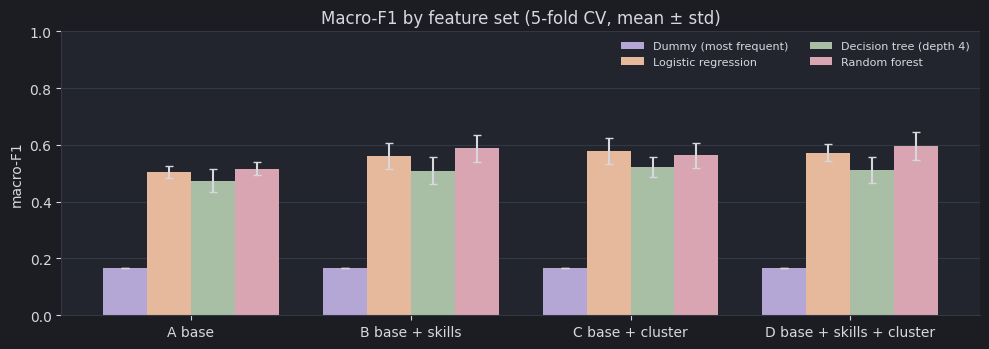

In [ ]:
# bar chart: one group of bars per clue set, one bar per model; the small line on each bar = std
fig, a = plt.subplots(figsize=(10, 3.6))
# bar width
w = 0.2
for i, mname in enumerate(models):
    # bar height = mean macro-F1
    v = [R.loc[(mname, s), "f1"] for s in SETS]
    # line length = std between the 5 parts
    e = [R.loc[(mname, s), "f1_std"] for s in SETS]
    a.bar(np.arange(len(SETS)) + (i - 1.5) * w, v, w, yerr=e, color=SOFT[i], capsize=3, ecolor=TEXT, label=mname)
a.set_xticks(range(len(SETS))); a.set_xticklabels(list(SETS))
a.set_ylim(0, 1); a.set_ylabel("macro-F1"); a.set_title("Macro-F1 by feature set (5-fold CV, mean ± std)")
a.legend(frameon=False, fontsize=8, ncol=2); a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 7. Did skills or clusters help?
**What this shows:** for each model, the macro-F1 change from adding skills (B minus A) and from adding the cluster label (C minus A), next to the fold std. Then the best model, and where it goes wrong.

In [ ]:
# the three real models (without the dummy)
real = [k for k in models if not k.startswith("Dummy")]
# for each model: compare the score with skills (B) and with cluster (C) against the basic score (A)
for mname in real:
    # a_, b_, c_ = scores of clue sets A, B, C
    a_, b_, c_ = (R.loc[(mname, s), "f1"] for s in ["A base", "B base + skills", "C base + cluster"])
    # sd = the biggest wobble between folds; a gain smaller than this could be luck
    sd = max(R.loc[(mname, s), "f1_std"] for s in ["A base", "B base + skills", "C base + cluster"])
    # a gain bigger than the wobble = 'helps clearly', otherwise 'no clear gain'
    word = lambda g: "helps clearly" if g > sd else "no clear gain"
    print(f"{mname:<24} skills {b_ - a_:+.3f} ({word(b_ - a_)}) | cluster {c_ - a_:+.3f} ({word(c_ - a_)}) | fold std about {sd:.3f}")
# all results without the dummy
cand = R.drop(index="Dummy (most frequent)", level="model")
# the model and clue set with the highest score
best_model, best_set = cand["f1"].idxmax()
# score of the dummy (the guessing floor)
dummy_f1 = R.loc[("Dummy (most frequent)", "A base"), "f1"]
# score of logistic regression on the basic clues (A): the baseline to beat
base_best = R.loc[("Logistic regression", "A base"), "f1"]
print(f"\nbest: {best_model} on '{best_set}' | macro-F1 {R.loc[(best_model, best_set), 'f1']:.3f} ± {R.loc[(best_model, best_set), 'f1_std']:.3f}")
print(f"dummy {dummy_f1:.3f} | logistic on A (the baseline) {base_best:.3f}")

Logistic regression      skills +0.057 (helps clearly) | cluster +0.074 (helps clearly) | fold std about 0.046
Decision tree (depth 4)  skills +0.035 (no clear gain) | cluster +0.048 (no clear gain) | fold std about 0.048
Random forest            skills +0.071 (helps clearly) | cluster +0.047 (no clear gain) | fold std about 0.049

best: Random forest on 'D base + skills + cluster' | macro-F1 0.595 ± 0.049
dummy 0.166 | logistic on A (the baseline) 0.504


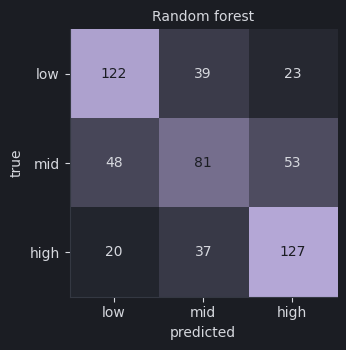

              precision    recall  f1-score   support

         low       0.64      0.66      0.65       184
         mid       0.52      0.45      0.48       182
        high       0.63      0.69      0.66       184

    accuracy                           0.60       550
   macro avg       0.59      0.60      0.60       550
weighted avg       0.59      0.60      0.60       550



In [ ]:
# band names in order
order = ["low", "mid", "high"]
# the best model's guess for every posting, made while that posting was hidden
pred = cross_val_predict(make(models[best_model], SETS[best_set]), X[SETS[best_set]], y, cv=cv)
# confusion matrix: rows = true band, columns = guessed band; the diagonal = correct guesses
cm = confusion_matrix(y, pred, labels=order)
# chart colors
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("soft", [PANEL, "#b4a7d6"])
fig, a = plt.subplots(figsize=(4.2, 3.6))
a.imshow(cm, cmap=cmap)
a.set_xticks(range(3)); a.set_xticklabels(order); a.set_yticks(range(3)); a.set_yticklabels(order)
a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(best_model, fontsize=10); a.grid(False)
# write the count inside each square
for i in range(3):
    for j in range(3):
        a.text(j, i, cm[i, j], ha="center", va="center", color=BG if cm[i, j] > cm.max() / 2 else TEXT)
plt.tight_layout(); plt.show()
# per band: precision (when it says this band, how often it is right),
# recall (of the real ones, how many it finds), f1 (a mix of both)
print(classification_report(y, pred, labels=order, digits=2))

random forest fitted on all rows only to read it, feature set: D base + skills + cluster


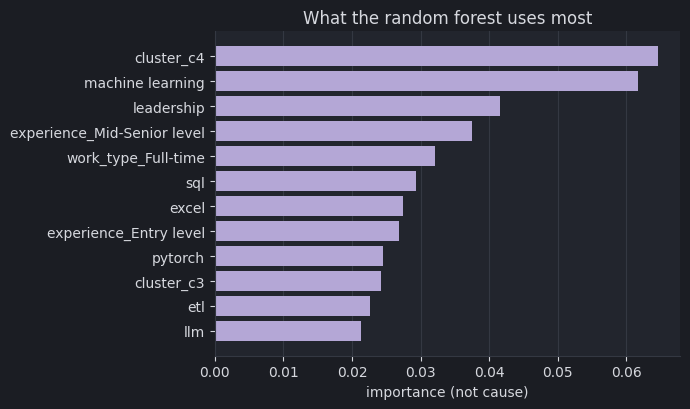

In [ ]:
#to see what the forest uses, give it all the clues (set D)
rf_set = "D base + skills + cluster"
#fit once on all rows, only to read it (not for scoring)
rf = make(models["Random forest"], SETS[rf_set]).fit(X[SETS[rf_set]], y)
#clue names; text clues are one-hot, e.g. experience_Entry level
names = [n.split("__", 1)[1] for n in rf[:-1].get_feature_names_out()]
#the 12 clues the forest uses most, flipped so the biggest is on top of the chart
imp = pd.Series(rf[-1].feature_importances_, index=names).sort_values(ascending=False).head(12)[::-1]
print("random forest fitted on all rows only to read it, feature set:", rf_set)
#importance = how much the forest used the clue. It shows use, not cause
fig, a = plt.subplots(figsize=(7, 4.2))
a.barh(imp.index, imp.values, color=SOFT[0]); a.set_xlabel("importance (not cause)")
a.set_title("What the random forest uses most"); a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 8. Checks before we trust it
**What this shows:** (1) no pay column is a feature (asserted in section 5); (2) label-shuffle test: the same best model on shuffled bands must fall to about random guessing (macro-F1 near 0.33). If it stays clearly higher, something leaks.
If cluster sets (C, D) are much higher than A and B, the cluster label may carry pay amounts from the description text. Write it in the last cell and test it later by removing numbers from the text before clustering.

In [ ]:
# shuffle the bands randomly: now the clues and the pay have no link at all
ys = pd.Series(np.random.RandomState(SEED).permutation(y.values), index=y.index)
# run the same best model on the shuffled bands
r = cross_validate(make(models[best_model], SETS[best_set]), X[SETS[best_set]], ys, cv=cv, scoring="f1_macro")
# should be about 0.33 (pure guessing). If it is much higher, something leaks the answer.
print("label-shuffle test, macro-F1:", round(r["test_score"].mean(), 3), "±", round(r["test_score"].std(), 3), "(random guessing is about 0.33)")

label-shuffle test, macro-F1: 0.332 ± 0.041 (random guessing is about 0.33)


## 9. YOUR RESULTS (edit this cell; write it in your own words)
- pay rows: 552 | after the join with skills and clusters: 550 | lost: 2
- best: Random forest on 'D base + skills + cluster' | macro-F1 0.595 ± 0.049
  dummy 0.166 | logistic on A (the baseline) 0.504
- Did skills help? (gain compared with the fold std):
  For Logistic Regression, adding skills (Feature Set B) increased the macro-F1 score by +0.057, which is larger than the fold standard deviation of 0.046.
  For the Random Forest model, adding skills (Feature Set B) increased the macro-F1 score by +0.071, which is also clearly larger than the fold standard deviation of 0.049.
- Did the cluster label help?
  Yes, it helps clearly in logistic regression (+0.074), but in the other models there is no clear gain beyond the fold standard deviation.
- The 3 features the random forest uses most, in plain words:
  1. Job Family Cluster C4
  2. 'Machine Learning' skill flag
  3. 'Leadership' skill flag
- Is the gain suspicious?
  Maybe: the +0.074 for logistic regression is bigger than the fold std (0.046), but clusters 0 and 1 are boilerplate text that includes pay words (range, compensation, total), so the cluster label may carry pay information. M4 test: remove money words from the text, re-cluster, re-run.
- Label-shuffle: macro-F1 0.332 ± 0.041 with shuffled bands = the same as random guessing (about 0.33), so the pipeline does not leak.
- Next step (M4): tune the random forest (train 0.85 against test 0.59), the leakage check above, and the final comparison table.